# Railway Track Fault Classification
**Module 1: Hybrid Feature Fusion & Random Forest Classifier**

**Workflow**:
1. Image Preprocessing & Data Augmentation (Blur, Grayscale, Noise, Flips)
2. Feature Extraction: YOLOv8 Backbone (Deep Features) + GLCM, Canny, RGB Histograms (Handcrafted Features)
3. Feature Fusion: $x_{fused} = x_{deep} \parallel x_{hand}$
4. Random Forest Model Training & Performance Evaluation
5. Explainable AI: SHAP Feature Importance Analysis

In [1]:
# Environment Setup & Library Imports
import os, sys
import cv2, torch, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add project root to sys.path
PROJECT_ROOT = os.path.abspath('..') if os.path.exists('../baseline') else os.path.abspath('.')
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print(f"Project Directory: {PROJECT_ROOT}")
print(f"PyTorch Version: {torch.__version__} | CPU Threads: {torch.get_num_threads()}")

Project Directory: /home/kom/projects/railway
PyTorch Version: 2.15.0+cpu | CPU Threads: 6


### 1. Data Preprocessing & Augmentation

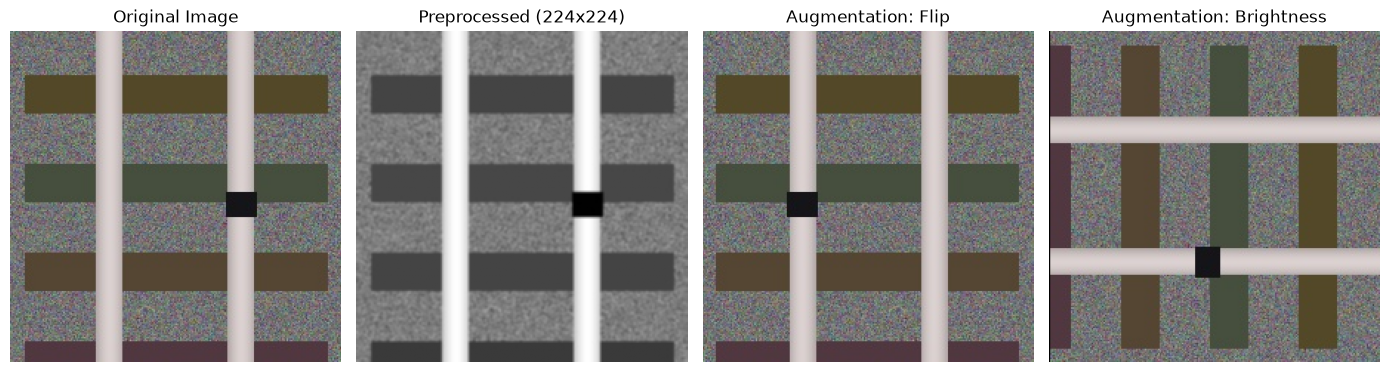

In [2]:
from baseline.preprocess import preprocess_image, augment_image

sample_img = os.path.join(PROJECT_ROOT, "data/baseline/Train/Defective/track_train_def_0001.jpg")
if os.path.exists(sample_img):
    orig = cv2.imread(sample_img)
    prep = preprocess_image(sample_img)
    augs = augment_image(orig)
    
    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    axes[0].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original Image")
    axes[0].axis("off")
    
    axes[1].imshow(prep, cmap="gray")
    axes[1].set_title("Preprocessed (224x224)")
    axes[1].axis("off")
    
    axes[2].imshow(cv2.cvtColor(augs[0], cv2.COLOR_BGR2RGB))
    axes[2].set_title("Augmentation: Flip")
    axes[2].axis("off")
    
    axes[3].imshow(cv2.cvtColor(augs[2], cv2.COLOR_BGR2RGB))
    axes[3].set_title("Augmentation: Brightness")
    axes[3].axis("off")
    plt.tight_layout()
    plt.show()

### 2. Feature Extraction & Vector Fusion

In [3]:
from baseline.extract_features import extract_yolo_features, extract_manual_features

if os.path.exists(sample_img):
    deep_feats = extract_yolo_features(sample_img)
    hand_feats = extract_manual_features(sample_img)
    fused_vector = deep_feats + hand_feats
    
    print(f"Deep Features (YOLOv8 Backbone): {len(deep_feats)}")
    print(f"Handcrafted Features (GLCM, Canny, RGB): {len(hand_feats)}")
    print(f"Total Fused Vector Dimension: {len(fused_vector)}")

Deep Features (YOLOv8 Backbone): 256
Handcrafted Features (GLCM, Canny, RGB): 20
Total Fused Vector Dimension: 276


### 3. Model Training & Evaluation

In [4]:
from baseline.train_rf import train_and_evaluate

train_csv = os.path.join(PROJECT_ROOT, "data/baseline/train_merged_features.csv")
val_csv = os.path.join(PROJECT_ROOT, "data/baseline/val_merged_features.csv")

if os.path.exists(train_csv):
    metrics = train_and_evaluate(train_csv, val_csv)
    print(f"Final Model Accuracy: {metrics['accuracy']:.2f}%")

 Baseline Random Forest Training & Evaluation
[*] Loaded training features: (1800, 278)
[*] Loaded validation features: (372, 278)
[*] Training Random Forest Classifier on CPU...
  - Features: 276 (Deep + Handcrafted)
  - Trees: 200, Max Depth: 15, Class Weight: balanced


  [✓] Model training completed!



 MODEL PERFORMANCE EVALUATION
  Accuracy:       98.92%
  Precision:      100.00%
  Recall:         97.85%
  F1-Score:       98.91%
  Jaccard Index:  97.85%
  MCC:            97.87%
  ROC-AUC:        99.99%
-----------------------------------------------------------------
Classification Report:
                precision    recall  f1-score   support

Non Defective       0.98      1.00      0.99       186
    Defective       1.00      0.98      0.99       186

     accuracy                           0.99       372
    macro avg       0.99      0.99      0.99       372
 weighted avg       0.99      0.99      0.99       372



[✓] Saved confusion matrix plot to /home/kom/projects/railway/docs/images/confusion_matrix.png
[✓] Saved ROC curve plot to /home/kom/projects/railway/docs/images/roc_curve.png


[✓] Saved trained Random Forest model to: /home/kom/projects/railway/models/random_forest_model.pkl
[✓] Saved scaler to: /home/kom/projects/railway/models/scaler.pkl
Final Model Accuracy: 98.92%


<Figure size 600x500 with 0 Axes>

### 4. Explainable AI Analysis (SHAP)

In [5]:
from baseline.explainability import run_shap_analysis

if os.path.exists(train_csv):
    shap_results = run_shap_analysis(train_csv, sample_size=50)
    print(f"Deep Features Contribution: {shap_results['yolo_ratio']*100:.1f}%")
    print(f"Handcrafted Features Contribution: {shap_results['manual_ratio']*100:.1f}%")

 Explainable AI (XAI) with SHAP for Railway Fault Detection
[*] Initializing SHAP TreeExplainer on 50 samples...


[✓] Saved SHAP feature importance plot to: /home/kom/projects/railway/docs/images/shap_feature_importance.png


[✓] Saved SHAP beeswarm plot to: /home/kom/projects/railway/docs/images/shap_beeswarm.png

 SHAP FEATURE CONTRIBUTION BREAKDOWN
  YOLOv8 Deep Features Contribution:     86.30%
  Handcrafted Domain Features (GLCM/etc): 13.70%
Deep Features Contribution: 86.3%
Handcrafted Features Contribution: 13.7%
